# 05 - Feature ranking

- Goal: rank the 17 original attributes with three filters: correlation, mutual information and mRMR.

- Reproduces: paper Sections 2.3 and 4.1.3, Table 10.

- Needs: nothing except utils.py. Writes results/rankings.csv, which notebook 06 reads.

- Expected run time: under 1 minute.

## 1. Setup
We rank the attributes on one train split (seed 42), before oversampling.

In [ ]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"  # Windows: set before the other imports

import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import mutual_info_score
from sklearn.model_selection import train_test_split

from utils import ALL_COLS, NUM_COLS, RESULT_DIR, SEED, load_data, set_style, show_table

N_REPEATS = 10  # paper uses 100 (not used here)
set_style()

## 2. Prepare the 17 attributes
We use only the 70% train part, so test data cannot influence the ranking. Categorical attributes keep whole-number codes, as in the paper. We code Month in calendar order and VisitorType in alphabetical order.

In [2]:
df = load_data()
month_codes = {"Feb": 2, "Mar": 3, "May": 5, "June": 6, "Jul": 7, "Aug": 8, "Sep": 9, "Oct": 10, "Nov": 11, "Dec": 12}
df["Month"] = df["Month"].map(month_codes)
df["VisitorType"] = df["VisitorType"].astype("category").cat.codes

train, _ = train_test_split(df, test_size=0.3, stratify=df["Revenue"], random_state=SEED)
print("Train rows used for ranking:", len(train))

Train rows used for ranking: 8631


## 3. Filter 1: correlation
A filter scores each attribute without training a model. Our first filter is the absolute correlation of each attribute with Revenue.

**Limitation**: correlation treats category codes as real numbers, but Browser 5 is not "more" than Browser 2. So its scores for categorical attributes are only rough.

In [3]:
corr_score = train[ALL_COLS].corrwith(train["Revenue"]).abs()
corr_rank = corr_score.sort_values(ascending=False).index.tolist()
corr_score.sort_values(ascending=False).round(3).head(5)

PageValues                 0.504
ExitRates                  0.211
ProductRelated             0.163
BounceRates                0.152
ProductRelated_Duration    0.149
dtype: float64

PageValues comes first with 0.504, far ahead of ExitRates at 0.211.

## 4. Discretise the continuous features
Mutual information needs values in groups, so we first turn each continuous feature into levels.

Paper Section 2.3 uses 9 levels. We compute z = (x - mean) / standard deviation. The level is 0 when z is between -0.5 and 0.5, and it goes up to +4 or down to -4 in steps of one standard deviation. Very large values stay at the end levels.

In [ ]:
def to_levels(x):
    # Discretise one continuous feature into the paper's 9 levels.
    z = (x - x.mean()) / x.std()
    levels = []
    for value in z:
        if abs(value) <= 0.5:
            levels.append(0)
        elif value > 0.5:
            levels.append(min(4, math.ceil(value - 0.5)))
        else:
            levels.append(-min(4, math.ceil(-value - 0.5)))
    return levels

discrete = train[ALL_COLS].copy()
for col in NUM_COLS:
    discrete[col] = to_levels(train[col])
print("Levels of ExitRates:", sorted(discrete["ExitRates"].unique()))

Levels of ExitRates: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


## 5. Filter 2: mutual information
Mutual information measures how much knowing one feature tells us about Revenue. Unlike correlation, it can also catch relations that are not straight lines.

In [5]:
mi_score = pd.Series({col: mutual_info_score(discrete[col], train["Revenue"]) for col in ALL_COLS})
mi_rank = mi_score.sort_values(ascending=False).index.tolist()
mi_score.sort_values(ascending=False).round(4).head(5)

PageValues                 0.1134
ExitRates                  0.0351
ProductRelated_Duration    0.0250
ProductRelated             0.0217
Administrative             0.0169
dtype: float64

PageValues comes first again, with 0.1134, followed by ExitRates at 0.0351.

## 6. Filter 3: mRMR
mRMR means minimum redundancy, maximum relevance. It picks features that are useful for predicting Revenue, but avoids features that repeat what the chosen ones already say.

We follow paper Eq. 11. We start with the feature with the highest mutual information. Each next feature must have the highest mutual information with Revenue minus its average mutual information with the features already chosen.

In [ ]:
def mrmr_rank(data, relevance):
    # Greedy mRMR: relevance minus average redundancy with the chosen features
    chosen = [relevance.idxmax()]
    left = [c for c in data.columns if c not in chosen]
    while left:
        scores = {}
        for col in left:
            redundancy = np.mean([mutual_info_score(data[col], data[c]) for c in chosen])
            scores[col] = relevance[col] - redundancy
        best = max(scores, key=scores.get)
        chosen.append(best)
        left.remove(best)
    return chosen

mrmr = mrmr_rank(discrete, mi_score)
print(mrmr[:6])

['PageValues', 'Month', 'ExitRates', 'Weekend', 'Informational_Duration', 'Region']


Our top 6 are PageValues, Month, ExitRates, Weekend, Informational_Duration and Region.

## 7. Table 10: rankings next to the paper
Each pair of columns shows our ranking and the paper's ranking for one filter. Look at the two mRMR columns first.

In [ ]:
paper_corr = ["PageValues", "ExitRates", "ProductRelated", "ProductRelated_Duration", "BounceRates",
              "Administrative", "VisitorType", "Informational", "Administrative_Duration", "SpecialDay",
              "Month", "TrafficType", "Informational_Duration", "OperatingSystems", "Weekend", "Region", "Browser"]
paper_mi = ["PageValues", "ExitRates", "ProductRelated_Duration", "BounceRates", "ProductRelated",
            "TrafficType", "Administrative", "Month", "Administrative_Duration", "Informational",
            "Informational_Duration", "VisitorType", "SpecialDay", "OperatingSystems", "Browser", "Weekend", "Region"]
paper_mrmr = ["PageValues", "Month", "ExitRates", "Weekend", "Informational_Duration", "Region",
              "OperatingSystems", "Administrative_Duration", "VisitorType", "ProductRelated_Duration",
              "SpecialDay", "Informational", "TrafficType", "Administrative", "BounceRates", "Browser", "ProductRelated"]

table = pd.DataFrame({
    "Correlation": corr_rank, "Correlation (paper)": paper_corr,
    "MI": mi_rank, "MI (paper)": paper_mi,
    "mRMR": mrmr, "mRMR (paper)": paper_mrmr,
}, index=range(1, 18))

table.index.name = "Rank"
show_table(table, "Table 10: feature rankings (ours vs paper)")

,Correlation,Correlation (paper),MI,MI (paper),mRMR,mRMR (paper)
Rank,,,,,,
1,PageValues,PageValues,PageValues,PageValues,PageValues,PageValues
2,ExitRates,ExitRates,ExitRates,ExitRates,Month,Month
3,ProductRelated,ProductRelated,ProductRelated_Duration,ProductRelated_Duration,ExitRates,ExitRates
4,BounceRates,ProductRelated_Duration,ProductRelated,BounceRates,Weekend,Weekend
5,ProductRelated_Duration,BounceRates,Administrative,ProductRelated,Informational_Duration,Informational_Duration
6,Administrative,Administrative,TrafficType,TrafficType,Region,Region
7,Month,VisitorType,Month,Administrative,Administrative_Duration,OperatingSystems
8,VisitorType,Informational,BounceRates,Month,OperatingSystems,Administrative_Duration
9,Administrative_Duration,Administrative_Duration,SpecialDay,Administrative_Duration,VisitorType,VisitorType


- Our mRMR ranking is almost the same as the paper's.
- The correlation and mutual information rankings are similar, but they differ in more places.

This next table measures how close we are. 

Spearman is a score of how similar two rankings are, where 1 means the same order. We also count how many of the top features are shared.

In [8]:
# Compare with the paper: rank correlation, and how many of the top 10 are shared.
rows = []
for name, ours, paper in [("Correlation", corr_rank, paper_corr), ("MI", mi_rank, paper_mi), ("mRMR", mrmr, paper_mrmr)]:
    a = pd.Series(range(17), index=ours)
    b = pd.Series(range(17), index=paper)
    rows.append({"Filter": name, "Spearman with paper": a.corr(b[a.index], method="spearman"),
                 "Top 10 shared": len(set(ours[:10]) & set(paper[:10])),
                 "Top 6 shared": len(set(ours[:6]) & set(paper[:6]))})
show_table(pd.DataFrame(rows).set_index("Filter"), "Agreement with the paper's rankings", digits=2)

,Spearman with paper,Top 10 shared,Top 6 shared
Filter,,,
Correlation,0.93,9,6
MI,0.94,9,5
mRMR,1.00,10,6


- mRMR shows 1.00 after rounding, and it shares all 10 of the top 10. 
- Correlation has 0.93 and shares 9 of the top 10. 
- Mutual information has 0.94 and shares 9 of the top 10. So we are close to the paper on all three, and nearly identical on mRMR.

## 8. Rank of each feature under each filter
Dark cells are near the top of a ranking. 

*Look for features that are dark under correlation and mutual information but pale under mRMR. Those are the redundant ones.*

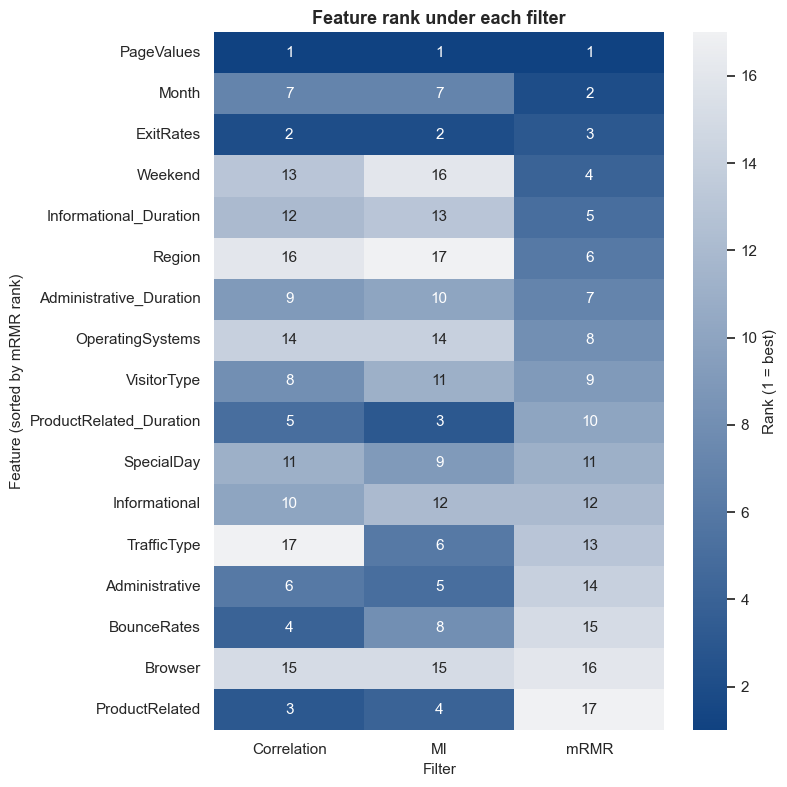

In [ ]:
ranks = pd.DataFrame({
    "Correlation": {c: i + 1 for i, c in enumerate(corr_rank)},
    "MI": {c: i + 1 for i, c in enumerate(mi_rank)},
    "mRMR": {c: i + 1 for i, c in enumerate(mrmr)},
}).loc[mrmr]

fig, ax = plt.subplots(figsize=(8, 8))
sns.heatmap(ranks, annot=True, fmt="d", cmap=sns.light_palette("#104281", reverse=True, as_cmap=True), cbar_kws={"label": "Rank (1 = best)"}, ax=ax)

ax.set_title("Feature rank under each filter")
ax.set_xlabel("Filter")
ax.set_ylabel("Feature (sorted by mRMR rank)")
plt.tight_layout()
plt.show()

BounceRates shows this pattern most clearly. It is rank 4 under correlation and rank 8 under mutual information, but rank 15 under mRMR, because it repeats ExitRates. 

ProductRelated is rank 3 and rank 4 under the first two filters and rank 17, the last place, under mRMR. ProductRelated_Duration falls to rank 10. 

This matches what the paper reports.

## 9. Save the rankings
Notebook 06 reads this file.

In [ ]:
os.makedirs(RESULT_DIR, exist_ok=True)
rankings = pd.DataFrame({"rank": range(1, 18), "correlation": corr_rank, "mutual_information": mi_rank, "mrmr": mrmr})
rankings.to_csv(f"{RESULT_DIR}/rankings.csv", index=False)
print("Saved", f"{RESULT_DIR}/rankings.csv")

Saved results/rankings.csv


## 10. Results at a glance

| Filter | Spearman with paper | Top 10 shared | Top 6 shared |
|---|---|---|---|
| Correlation | 0.93 | 9 | 6 |
| Mutual information | 0.94 | 9 | 5 |
| mRMR | 1.00 | 10 | 6 |

- PageValues comes first in all three rankings, as in the paper. 

- Our mRMR ranking almost exactly matches the paper, and that is our closest replication in the whole project.

- Getting the ranking right does not mean the classifier also matches the paper, and notebook 06 tests that separately.

## 11. Key takeaways

1. PageValues is first in all three rankings, as in the paper. 
2. Our mRMR top 6 are the same features in the same order as the paper. The only change in all 17 ranks is that ranks 7 and 8 swap.

3. mRMR pushes redundant features down, just as the paper says. BounceRates falls to rank 15 because it repeats ExitRates (correlation 0.91, notebook 01). ProductRelated falls to rank 17 and ProductRelated_Duration to rank 10.

4. The ranking has limits. It uses one train split (seed 42), and later repeats reuse it, so it has seen rows that later become test data. We expect this effect to be small, but we did not measure it. Mutual information also tends to favour attributes with many categories.